# AI-Powered Driver Distraction Detection System

**Project goal:** Classify driver images into 10 driving-behavior classes using a custom CNN and transfer-learning models.

**Models:** Custom CNN, MobileNetV2, EfficientNetB0.

**Dataset:** State Farm Distracted Driver Detection (Kaggle).

## 1. Check TensorFlow and GPU

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Install KaggleHub

In [2]:
!pip install -q kagglehub

## 3. Authenticate with Kaggle

In [3]:

!pip -q install -U kagglehub

import kagglehub

# Opens a secure token input prompt
kagglehub.login()

# Download the competition dataset
path = kagglehub.competition_download(
    "state-farm-distracted-driver-detection"
)

print("Dataset downloaded successfully!")
print("Location:", path)


100%|██████████| 4.00G/4.00G [01:01<00:00, 69.6MB/s]

Extracting files...


Dataset downloaded successfully!
Location: /root/.cache/kagglehub/competitions/state-farm-distracted-driver-detection
Kaggle credentials set.
Kaggle credentials successfully validated.


## 4. Access the dataset

In [6]:
dataset_path = kagglehub.competition_download(
    "state-farm-distracted-driver-detection"
)

print("Dataset path:", dataset_path)
print(os.listdir(dataset_path))

Dataset path: /root/.cache/kagglehub/competitions/state-farm-distracted-driver-detection
['sample_submission.csv', 'imgs', 'driver_imgs_list.csv']


## 5. Explore the dataset and visualize sample images

Dataset shape: (22424, 3)

Class distribution:
classname
c0    2489
c1    2267
c2    2317
c3    2346
c4    2326
c5    2312
c6    2325
c7    2002
c8    1911
c9    2129
Name: count, dtype: int64


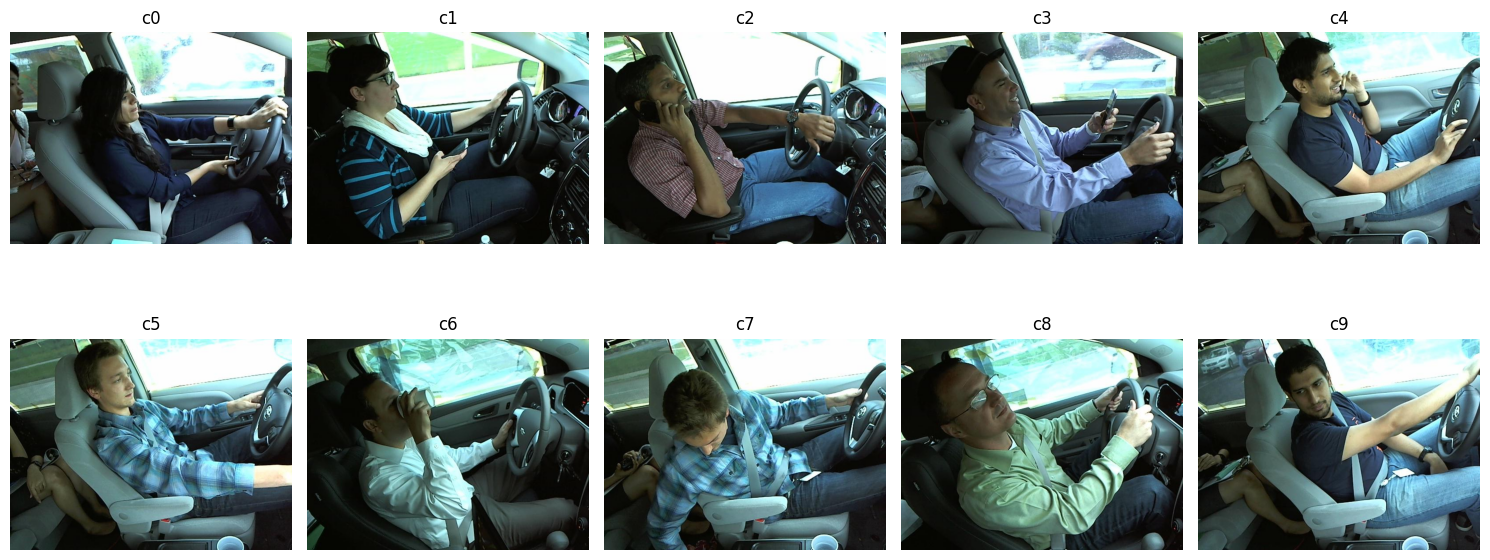

In [7]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

train_path = os.path.join(dataset_path, "imgs", "train")

df = pd.read_csv(os.path.join(dataset_path, "driver_imgs_list.csv"))

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["classname"].value_counts().sort_index())

# Display sample images
classes = sorted(os.listdir(train_path))
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, cls in zip(axes.flatten(), classes):
    img_name = random.choice(os.listdir(os.path.join(train_path, cls)))
    img = Image.open(os.path.join(train_path, cls, img_name))
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Prepare training and validation datasets

In [8]:

import tensorflow as tf
from sklearn.model_selection import train_test_split

IMG_SIZE = 128
BATCH_SIZE = 32
SEED = 42

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED,
    stratify=df["classname"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=SEED
)

print("Class names:", train_ds.class_names)


Training images: 17939
Validation images: 4485
Found 22424 files belonging to 10 classes.
Using 17940 files for training.
Found 22424 files belonging to 10 classes.
Using 4484 files for validation.
Class names: ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


## 7. Model 1 — Custom CNN: build and train

In [9]:

import tensorflow as tf
from tensorflow.keras import layers, models

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(2000, seed=42).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 80s 61ms/step - accuracy: 0.1356 - loss: 2.2653 - val_accuracy: 0.1744 - val_loss: 2.1789
Epoch 2/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.2719 - loss: 1.8853 - val_accuracy: 0.3481 - val_loss: 1.6274
Epoch 3/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.3856 - loss: 1.5146 - val_accuracy: 0.4746 - val_loss: 1.3130
Epoch 4/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.5053 - loss: 1.2505 - val_accuracy: 0.5580 - val_loss: 1.1149
Epoch 5/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.6120 - loss: 1.0191 - val_accuracy: 0.7190 - val_loss: 0.8635


### 7.1 CNN training curves

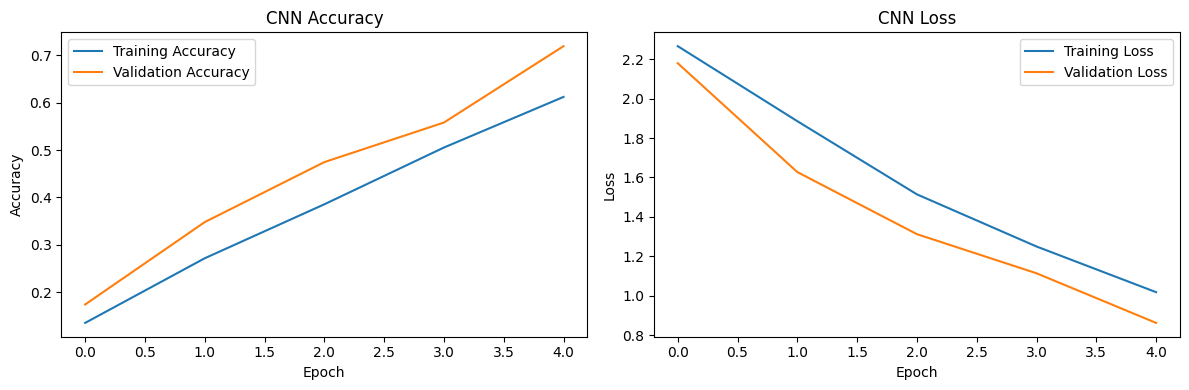

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


### 7.2 CNN validation evaluation

In [11]:

cnn_loss, cnn_accuracy = cnn_model.evaluate(val_ds, verbose=1)

print(f"CNN Validation Accuracy: {cnn_accuracy * 100:.2f}%")
print(f"CNN Validation Loss: {cnn_loss:.4f}")


141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7190 - loss: 0.8635
CNN Validation Accuracy: 71.90%
CNN Validation Loss: 0.8635


## 8. Model 2 — MobileNetV2: build

In [12]:

import tensorflow as tf
from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(128, 128, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

mobilenet_model = models.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 8.1 Train MobileNetV2

In [13]:

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 59s 67ms/step - accuracy: 0.6077 - loss: 1.2163 - val_accuracy: 0.8925 - val_loss: 0.4974
Epoch 2/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8419 - loss: 0.5439 - val_accuracy: 0.9277 - val_loss: 0.3294
Epoch 3/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8765 - loss: 0.4154 - val_accuracy: 0.9387 - val_loss: 0.2553
Epoch 4/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8932 - loss: 0.3566 - val_accuracy: 0.9456 - val_loss: 0.2196
Epoch 5/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8998 - loss: 0.3262 - val_accuracy: 0.9398 - val_loss: 0.2200


## 9. Model 3 — EfficientNetB0: build

In [14]:

import tensorflow as tf
from tensorflow.keras import layers, models

base_eff = tf.keras.applications.EfficientNetB0(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_eff.trainable = False

inputs = layers.Input(shape=(128, 128, 3))

# EfficientNetB0 includes its own input rescaling
x = base_eff(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

efficientnet_model = models.Model(inputs, outputs)

efficientnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### 9.1 Train EfficientNetB0

In [15]:

history_eff = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 106s 119ms/step - accuracy: 0.5808 - loss: 1.3567 - val_accuracy: 0.8341 - val_loss: 0.7845
Epoch 2/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7833 - loss: 0.7887 - val_accuracy: 0.8854 - val_loss: 0.5448
Epoch 3/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8206 - loss: 0.6359 - val_accuracy: 0.9213 - val_loss: 0.4231
Epoch 4/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8424 - loss: 0.5608 - val_accuracy: 0.9295 - val_loss: 0.3575
Epoch 5/5
561/561 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8557 - loss: 0.5019 - val_accuracy: 0.9331 - val_loss: 0.3157


## 10. Compare training curves for CNN and MobileNetV2

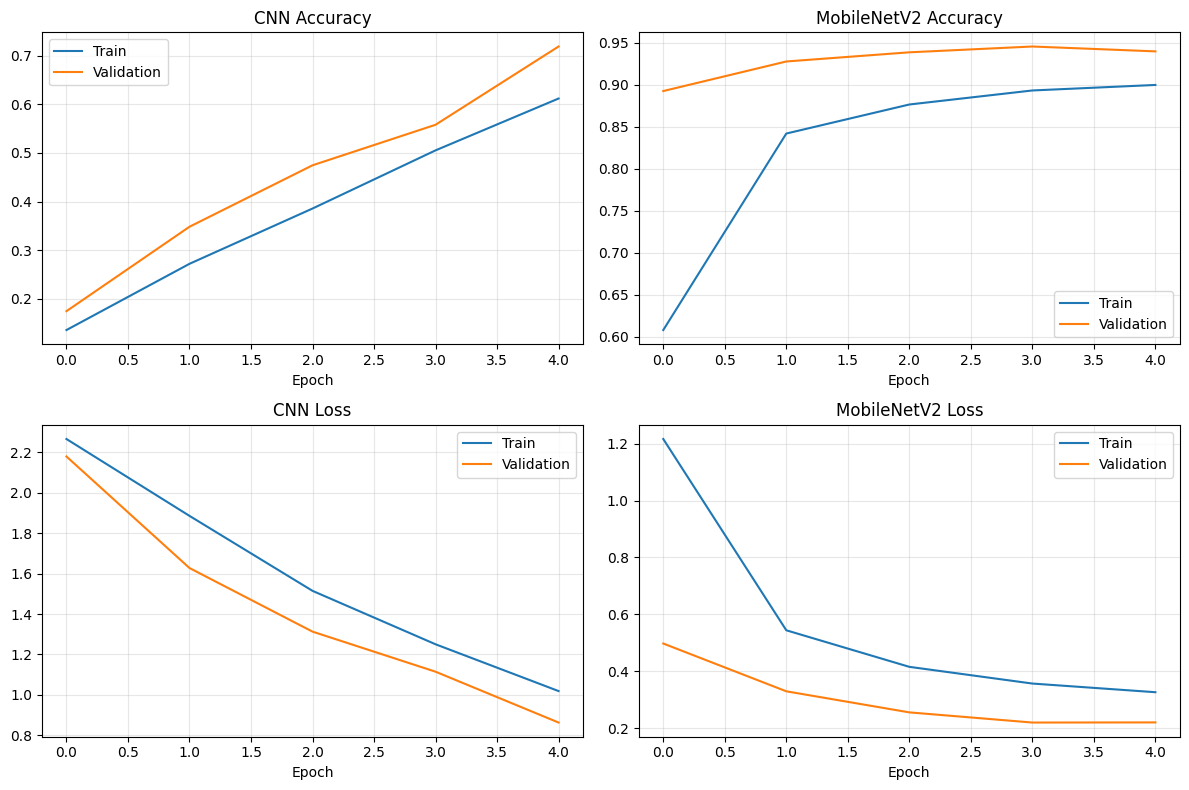

In [16]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(history_cnn.history["accuracy"], label="Train")
axes[0, 0].plot(history_cnn.history["val_accuracy"], label="Validation")
axes[0, 0].set_title("CNN Accuracy")
axes[0, 0].legend()

axes[0, 1].plot(history_mobilenet.history["accuracy"], label="Train")
axes[0, 1].plot(history_mobilenet.history["val_accuracy"], label="Validation")
axes[0, 1].set_title("MobileNetV2 Accuracy")
axes[0, 1].legend()

axes[1, 0].plot(history_cnn.history["loss"], label="Train")
axes[1, 0].plot(history_cnn.history["val_loss"], label="Validation")
axes[1, 0].set_title("CNN Loss")
axes[1, 0].legend()

axes[1, 1].plot(history_mobilenet.history["loss"], label="Train")
axes[1, 1].plot(history_mobilenet.history["val_loss"], label="Validation")
axes[1, 1].set_title("MobileNetV2 Loss")
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 11. MobileNetV2 classification report and confusion matrix

141/141 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step
MobileNetV2 Classification Report:
              precision    recall  f1-score   support

          c0     0.9617    0.8933    0.9262       506
          c1     0.9204    0.9885    0.9532       433
          c2     0.9345    0.9772    0.9554       482
          c3     0.8844    0.9787    0.9291       422
          c4     0.9475    0.9116    0.9292       475
          c5     0.9853    0.9811    0.9832       477
          c6     0.9075    0.9483    0.9275       445
          c7     0.9772    0.9797    0.9785       394
          c8     0.9450    0.7745    0.8513       377
          c9     0.9413    0.9493    0.9453       473

    accuracy                         0.9398      4484
   macro avg     0.9405    0.9382    0.9379      4484
weighted avg     0.9409    0.9398    0.9390      4484



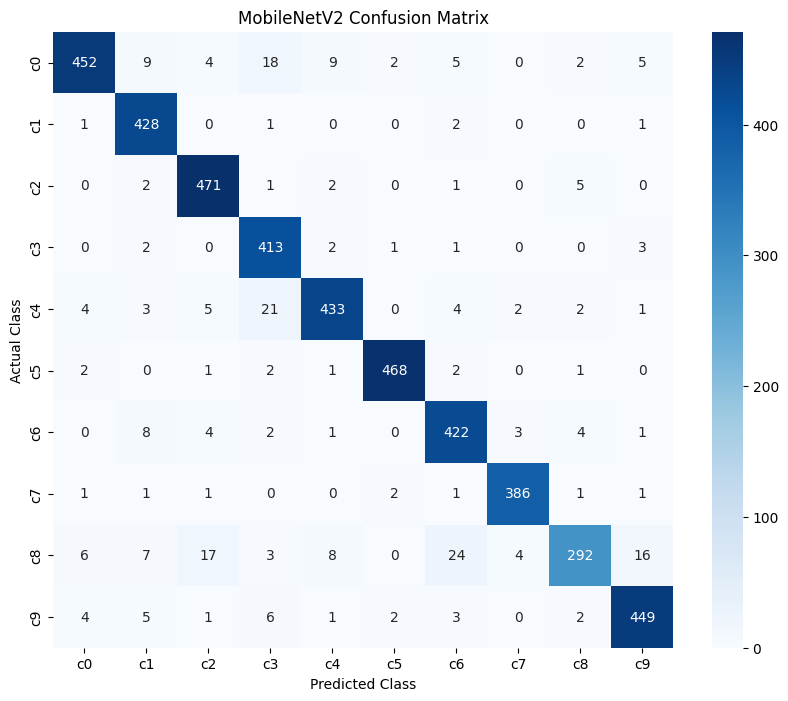

In [17]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

class_names = [f"c{i}" for i in range(10)]

y_true = np.concatenate([y.numpy() for x, y in val_ds])
y_prob = mobilenet_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("MobileNetV2 Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()


## 12. Visualize sample predictions from dataset images

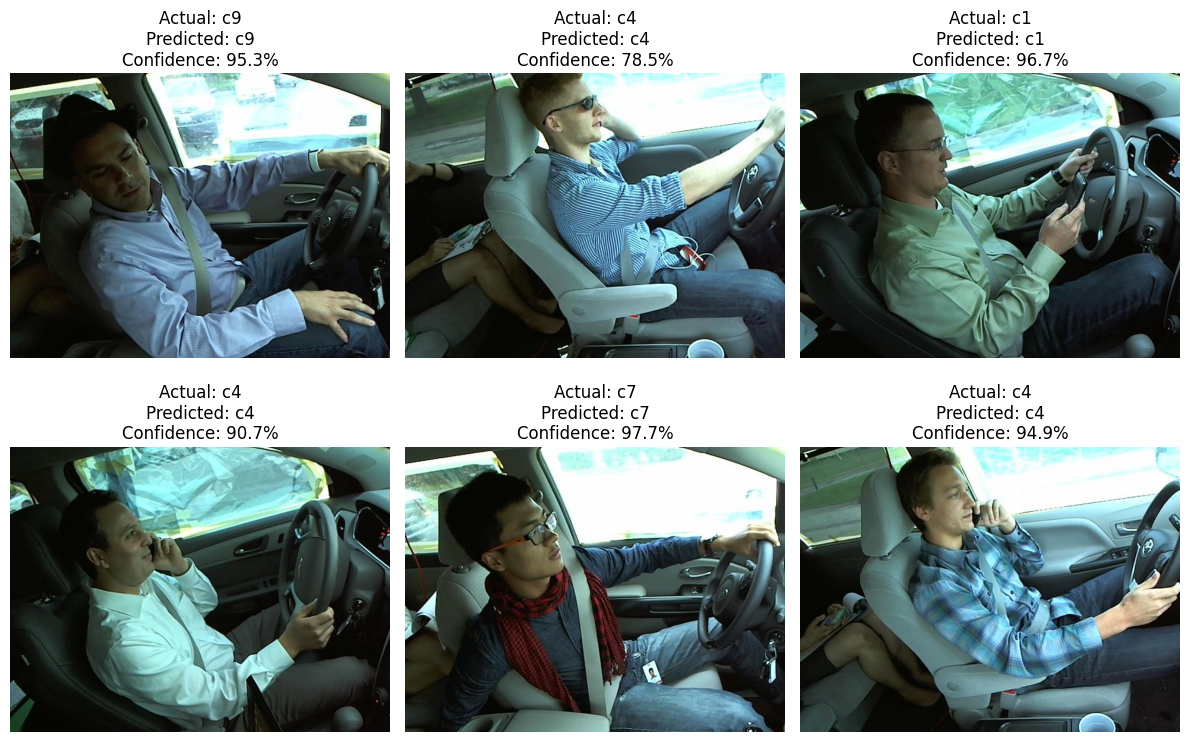

In [18]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

class_names = [f"c{i}" for i in range(10)]
train_path = os.path.join(dataset_path, "imgs", "train")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    cls = random.choice(class_names)
    folder = os.path.join(train_path, cls)
    filename = random.choice(os.listdir(folder))
    image_path = os.path.join(folder, filename)

    img = load_img(image_path, target_size=(128, 128))
    arr = img_to_array(img)
    probabilities = mobilenet_model.predict(
        np.expand_dims(arr, axis=0), verbose=0
    )[0]

    predicted_idx = np.argmax(probabilities)
    confidence = probabilities[predicted_idx] * 100

    ax.imshow(load_img(image_path))
    ax.set_title(
        f"Actual: {cls}\nPredicted: {class_names[predicted_idx]}\n"
        f"Confidence: {confidence:.1f}%"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


## 13. Compare all three models

,Model,Training Accuracy (%),Validation Accuracy (%),Validation Loss
0,Custom CNN,61.1984,71.9001,0.8635
1,MobileNetV2,89.9777,93.9786,0.2200
2,EfficientNetB0,85.5741,93.3095,0.3157


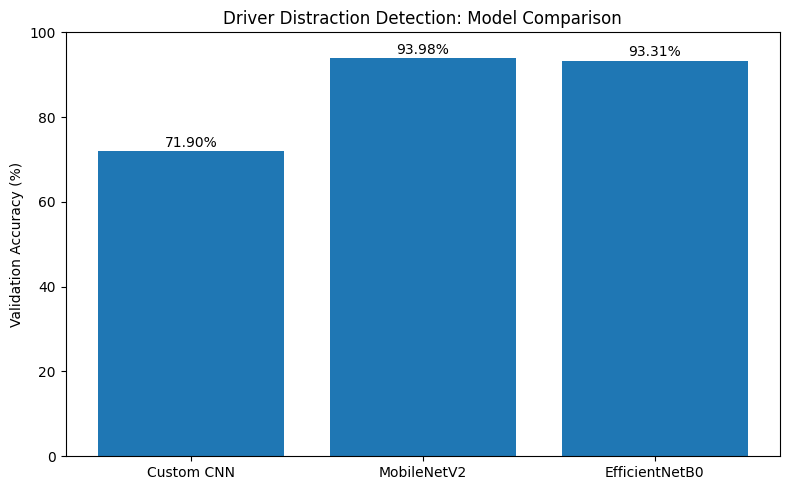

In [19]:

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2", "EfficientNetB0"],
    "Training Accuracy (%)": [
        history_cnn.history["accuracy"][-1] * 100,
        history_mobilenet.history["accuracy"][-1] * 100,
        history_eff.history["accuracy"][-1] * 100
    ],
    "Validation Accuracy (%)": [
        history_cnn.history["val_accuracy"][-1] * 100,
        history_mobilenet.history["val_accuracy"][-1] * 100,
        history_eff.history["val_accuracy"][-1] * 100
    ],
    "Validation Loss": [
        history_cnn.history["val_loss"][-1],
        history_mobilenet.history["val_loss"][-1],
        history_eff.history["val_loss"][-1]
    ]
})

display(results.round(4))

plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["Validation Accuracy (%)"])
plt.ylabel("Validation Accuracy (%)")
plt.title("Driver Distraction Detection: Model Comparison")
plt.ylim(0, 100)

for i, value in enumerate(results["Validation Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


## 14. Save all three trained models

In [20]:

cnn_model.save("/content/driver_distraction_cnn.keras")
mobilenet_model.save("/content/driver_distraction_mobilenet.keras")
efficientnet_model.save("/content/driver_distraction_efficientnet.keras")

print("All 3 models saved successfully!")


All 3 models saved successfully!


### 14.1 Package the models into a ZIP file

In [21]:

import zipfile
import os

model_files = [
    "/content/driver_distraction_cnn.keras",
    "/content/driver_distraction_mobilenet.keras",
    "/content/driver_distraction_efficientnet.keras"
]

zip_path = "/content/driver_distraction_models.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in model_files:
        z.write(file, os.path.basename(file))

print("ZIP created:", zip_path)


ZIP created: /content/driver_distraction_models.zip


### 14.2 Download the ZIP file

In [22]:

from google.colab import files
files.download("/content/driver_distraction_models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Predict driver behavior from an uploaded image

Saving Screenshot 2026-10-23 140801.png to Screenshot 2026-10-23 140801.png


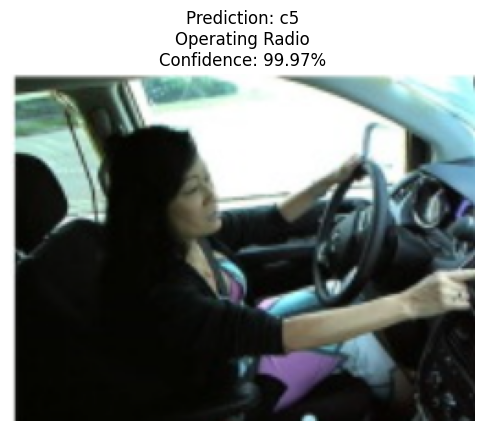

Class probabilities:
c0 (Safe Driving): 0.01%
c1 (Texting - Right Hand): 0.00%
c2 (Talking on Phone - Right Hand): 0.00%
c3 (Texting - Left Hand): 0.00%
c4 (Talking on Phone - Left Hand): 0.00%
c5 (Operating Radio): 99.97%
c6 (Drinking): 0.00%
c7 (Reaching Behind): 0.00%
c8 (Hair and Makeup): 0.00%
c9 (Talking to Passenger): 0.01%


In [23]:

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

class_names = [
    "Safe Driving",
    "Texting - Right Hand",
    "Talking on Phone - Right Hand",
    "Texting - Left Hand",
    "Talking on Phone - Left Hand",
    "Operating Radio",
    "Drinking",
    "Reaching Behind",
    "Hair and Makeup",
    "Talking to Passenger"
]

for filename in uploaded:
    img = load_img(filename, target_size=(128, 128))
    arr = img_to_array(img)

    probabilities = mobilenet_model.predict(
        np.expand_dims(arr, axis=0), verbose=0
    )[0]

    predicted_idx = np.argmax(probabilities)
    confidence = probabilities[predicted_idx] * 100

    plt.figure(figsize=(6, 5))
    plt.imshow(load_img(filename))
    plt.axis("off")
    plt.title(
        f"Prediction: c{predicted_idx}\n"
        f"{class_names[predicted_idx]}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Class probabilities:")
    for i, score in enumerate(probabilities):
        print(f"c{i} ({class_names[i]}): {score * 100:.2f}%")
